# 00 · Análisis exploratorio del dataset

Corpus ya scrapeado, filtrado, deduplicado y dividido por `DatasetInsectos`
(`manifiesto.json`, semilla 42, reparto por observación). Este notebook solo lo
inspecciona: nunca recalcula el split ni toca las imágenes.

In [1]:
import os
from pathlib import Path

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
    os.chdir(ROOT)

print("Raíz del proyecto:", ROOT)

Raíz del proyecto: /home/santiago/projects/proyecto_semillero/ModeladoInsectos


In [2]:
import pandas as pd

from scripts import corpus
from scripts.vizStyle import SERIE_1, SERIE_2, SERIE_3, applyStyle, limpiarEje

corpus.materializar()
manifiesto = corpus.manifiesto()
parametros = manifiesto["parametros"]
print(f"semilla {parametros['semilla']} · {manifiesto['num_clases']} clases · {manifiesto['conteos']}")
print("fusiones:", parametros.get("fusiones", {}))

semilla 42 · 35 clases · {'train': 9554, 'test': 2724, 'validate': 1347, 'total': 13625}
fusiones: {'atta_cephalotes': 'atta_spp', 'atta_colombica': 'atta_spp'}


## 1 · Conteo por clase y por split

In [3]:
reparto = manifiesto["reparto"]
filas = [
    {"clase": clase, **{s: len(archivos[s]) for s in ("train", "test", "validate")}}
    for clase, archivos in reparto.items()
]
conteos = pd.DataFrame(filas)
conteos["total"] = conteos[["train", "test", "validate"]].sum(axis=1)
conteos = conteos.sort_values("total", ascending=False).reset_index(drop=True)
conteos.describe()

,train,test,validate,total
count,35.000000,35.000000,35.000000,35.000000
mean,272.971429,77.828571,38.485714,389.285714
std,36.303043,10.570452,5.425275,52.177622
min,173.000000,49.000000,23.000000,245.000000
25%,253.000000,72.000000,35.500000,360.500000
50%,285.000000,80.000000,40.000000,406.000000
75%,299.500000,84.500000,42.500000,426.000000
max,319.000000,91.000000,46.000000,456.000000


In [4]:
print(f"{len(conteos)} clases, {conteos['total'].sum()} imágenes totales")
conteos[["train", "test", "validate", "total"]].sum().to_frame("imagenes")

35 clases, 13625 imágenes totales


,imagenes
train,9554
test,2724
validate,1347
total,13625


## 2 · Balance del corpus

Con cuántas imágenes queda la clase más escasa y la más abundante — define
qué tanto pesa `class_weight="balanced"` en el entrenamiento.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


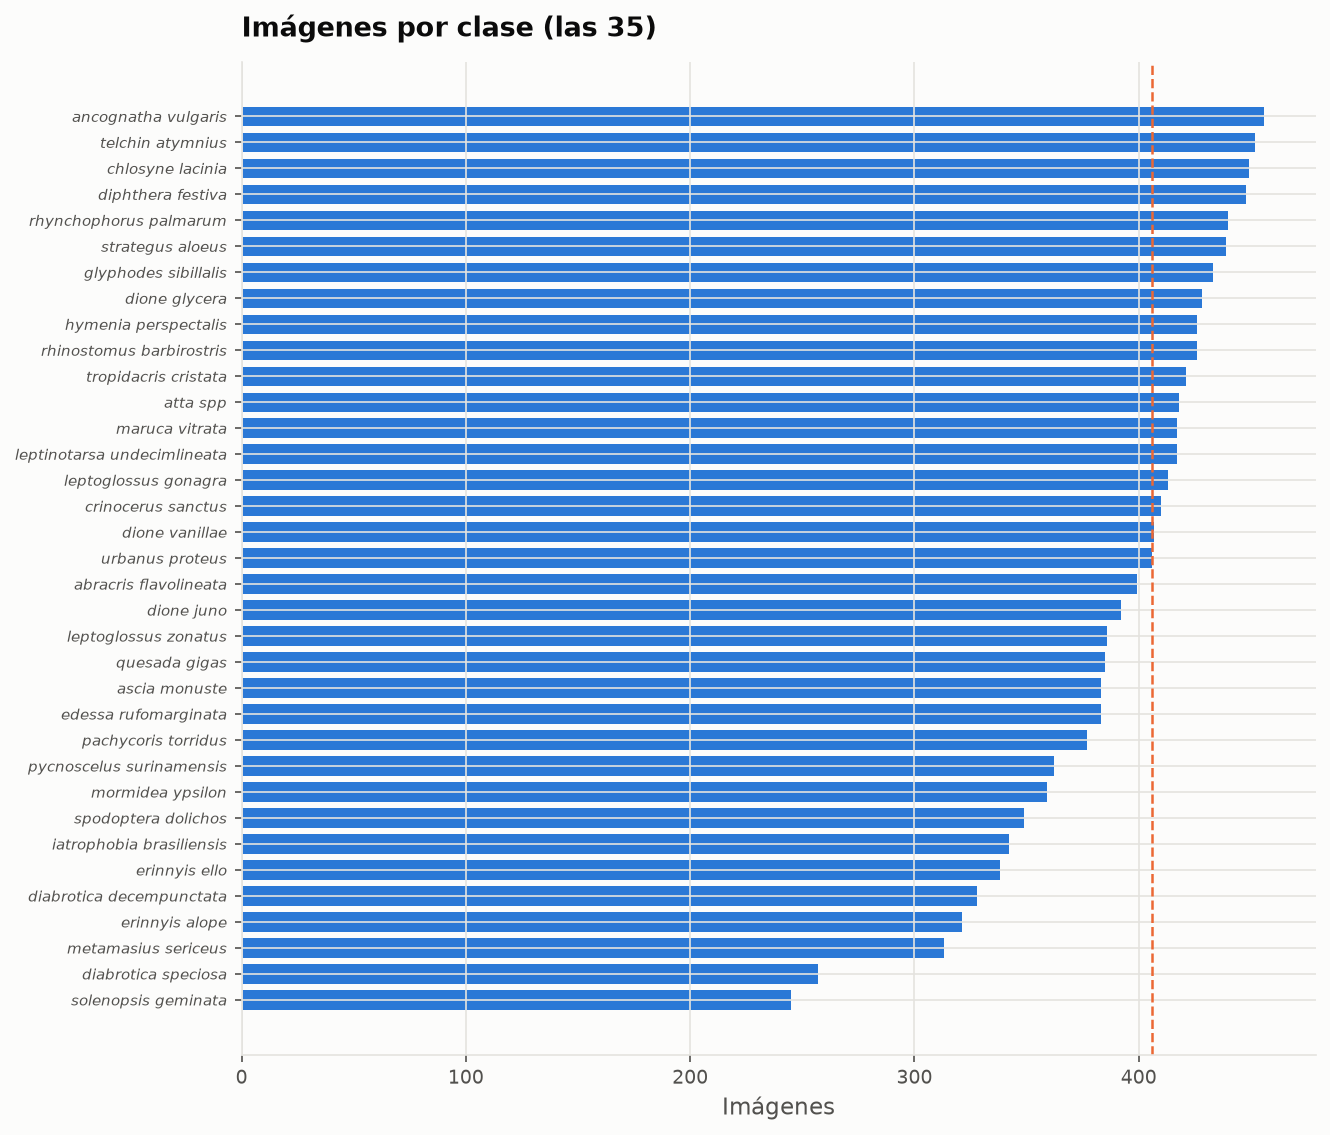

In [5]:
applyStyle()
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, max(4, 0.22 * len(conteos))))
ax.barh(range(len(conteos)), conteos["total"], color=SERIE_1, height=0.75)
ax.set_yticks(range(len(conteos)), [c.replace("_", " ") for c in conteos["clase"]],
              fontsize=7, style="italic")
ax.invert_yaxis()
ax.set(xlabel="Imágenes", title=f"Imágenes por clase (las {len(conteos)})")
ax.axvline(conteos["total"].median(), color=SERIE_2, linestyle="--", linewidth=1.2)
fig.tight_layout()
plt.show()

In [6]:
mayor, menor = conteos.iloc[0], conteos.iloc[-1]
print(f"Más imágenes : {mayor['clase']} ({mayor['total']})")
print(f"Menos imágenes: {menor['clase']} ({menor['total']})")
print(f"Razón mayor/menor: {mayor['total'] / menor['total']:.2f}")

Más imágenes : ancognatha_vulgaris (456)
Menos imágenes: solenopsis_geminata (245)
Razón mayor/menor: 1.86


## 3 · Pesos de clase

Los que recibe `fit()` como `class_weight`, calculados con los conteos de train.
Cerca de 1 en todas las clases significa que el balanceo apenas interviene.

In [7]:
pesosClase = corpus.classWeights()
nombres = corpus.classNames()
pesos = pd.Series({nombres[i]: round(p, 3) for i, p in pesosClase.items()}, name="peso")
pd.concat([pesos.sort_values(ascending=False).head(5),
           pesos.sort_values().head(5)]).to_frame()

,peso
solenopsis_geminata,1.578
diabrotica_speciosa,1.517
metamasius_sericeus,1.230
erinnyis_alope,1.213
diabrotica_decempunctata,1.177
ancognatha_vulgaris,0.856
telchin_atymnius,0.864
diphthera_festiva,0.869
chlosyne_lacinia,0.869
rhynchophorus_palmarum,0.881


## 4 · Proporción del split por clase

El reparto es 70/20/10 por observación, con la semilla combinada con la clase;
se verifica que se cumpla incluso en las clases más escasas.

In [8]:
proporciones = conteos.copy()
for s in ("train", "test", "validate"):
    proporciones[f"{s}_pct"] = proporciones[s] / proporciones["total"]
proporciones[["clase", "total", "train_pct", "test_pct", "validate_pct"]].describe()

,total,train_pct,test_pct,validate_pct
count,35.000000,35.000000,35.000000,35.000000
mean,389.285714,0.701333,0.199885,0.098782
std,52.177622,0.002440,0.002950,0.002174
min,245.000000,0.698830,0.191693,0.093506
25%,360.500000,0.699739,0.198573,0.097561
50%,406.000000,0.700713,0.199561,0.099307
75%,426.000000,0.701768,0.201492,0.100530
max,456.000000,0.709265,0.205195,0.101167


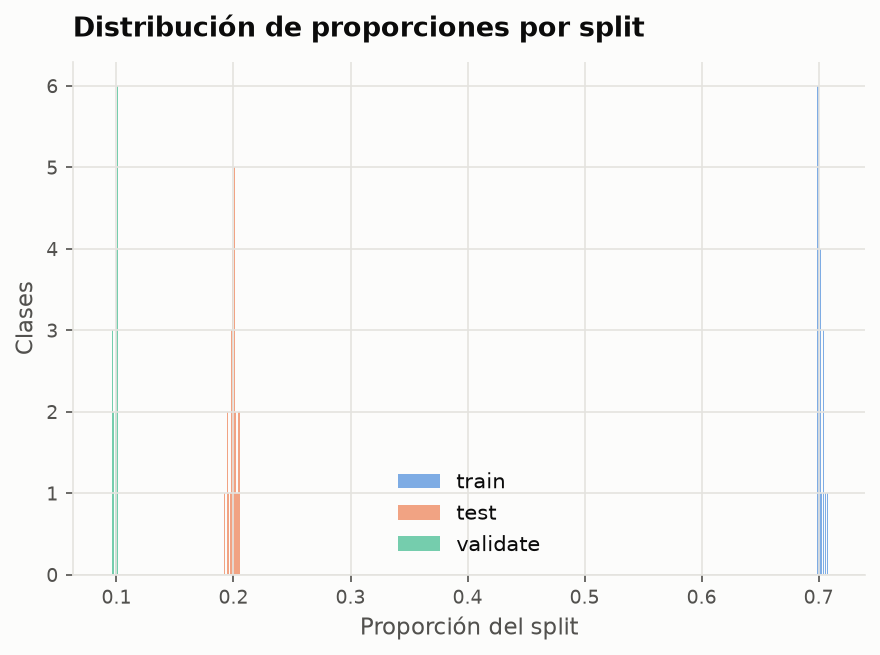

In [9]:
applyStyle()
fig, ax = plt.subplots(figsize=(6, 4.5))
for col, color, label in (
    ("train_pct", SERIE_1, "train"),
    ("test_pct", SERIE_2, "test"),
    ("validate_pct", SERIE_3, "validate"),
):
    ax.hist(proporciones[col], bins=20, color=color, alpha=0.6, label=label)
ax.set(xlabel="Proporción del split", ylabel="Clases", title="Distribución de proporciones por split")
ax.legend()
fig.tight_layout()
plt.show()

## 5 · Un ejemplo por clase

Primera imagen de train de cada clase, para ver de un vistazo si el recorte
encuadra al insecto (o la agalla, en *Iatrophobia*).

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


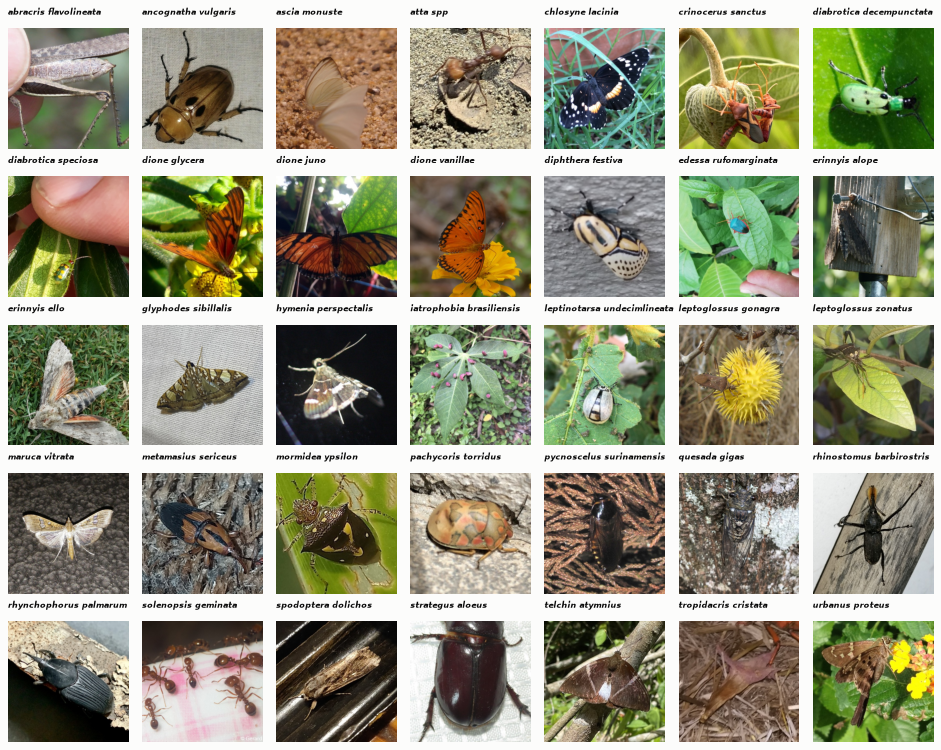

In [10]:
from PIL import Image

clases = sorted(reparto)
columnas = 7
filasGrilla = -(-len(clases) // columnas)

applyStyle()
fig, ejes = plt.subplots(filasGrilla, columnas, figsize=(1.7 * columnas, 1.9 * filasGrilla), dpi=80)
for ax in ejes.flat:
    limpiarEje(ax)
for ax, clase in zip(ejes.flat, clases):
    archivo = reparto[clase]["train"][0]
    ax.imshow(Image.open(Path("dataset/train") / clase / archivo))
    ax.set_title(clase.replace("_", " "), fontsize=7, style="italic")
fig.tight_layout()
plt.show()

## 6 · Tamaño de imagen

In [11]:
tamanos = set()
for clase in clases:
    for archivo in reparto[clase]["train"][:3]:
        tamanos.add(Image.open(Path("dataset/train") / clase / archivo).size)
print("Tamaños encontrados en la muestra:", tamanos)

Tamaños encontrados en la muestra: {(448, 448)}


## 7 · Observaciones independientes en test

Varias fotos pueden venir de la misma observación de iNaturalist (el mismo
individuo). El reparto por observación evita que crucen de train a test, pero
dentro de test no son independientes: el tamaño efectivo para estimar el
acierto de una clase es su número de observaciones, no de fotos.

Lee `auditoria.csv` del repositorio hermano, así que solo corre en local.

In [12]:
rutaAuditoria = corpus.repoDataset() / "auditoria.csv"
if rutaAuditoria.exists():
    fusiones = parametros.get("fusiones", {})
    auditoria = pd.read_csv(rutaAuditoria, usecols=["especie", "observation_id", "motivo", "split"])
    aceptadas = auditoria[auditoria["motivo"] == "aceptada"].copy()
    aceptadas["clase"] = aceptadas["especie"].map(lambda e: fusiones.get(e, e))
    porClase = (aceptadas[aceptadas["split"] == "test"].groupby("clase")
                .agg(fotos=("observation_id", "size"), observaciones=("observation_id", "nunique")))
    porClase["fotos_por_obs"] = (porClase["fotos"] / porClase["observaciones"]).round(2)
    print(f"test: {porClase['fotos'].sum()} fotos de {porClase['observaciones'].sum()} observaciones")
    display(porClase.sort_values("observaciones").head(8))
else:
    print(f"No hay {rutaAuditoria}: esta sección solo corre con el repositorio hermano en local")

test: 2724 fotos de 1884 observaciones


,fotos,observaciones,fotos_por_obs
clase,,,
solenopsis_geminata,49,27,1.81
erinnyis_alope,65,30,2.17
pachycoris_torridus,75,34,2.21
diabrotica_speciosa,51,35,1.46
metamasius_sericeus,60,37,1.62
strategus_aloeus,89,42,2.12
erinnyis_ello,67,42,1.60
diabrotica_decempunctata,64,45,1.42


## Resumen

- 35 clases (con *Atta cephalotes* y *A. colombica* fusionadas en `atta_spp`),
  13 625 imágenes, reparto 70/20/10 por observación ya armado por
  `DatasetInsectos` (semilla 42).
- Imágenes de 448×448 RGB, el mismo `IMG_SIZE` con que se entrena: no se
  reescalan.
- El corpus está casi balanceado: entre 245 (*Solenopsis geminata*) y 456
  (*Ancognatha vulgaris*) imágenes por clase, una razón menor a 2, así que
  `class_weight="balanced"` apenas corrige (pesos entre ~0.86 y ~1.58).
- Las 2 724 fotos de test vienen de 1 884 observaciones; la clase con menos
  (*Solenopsis geminata*) tiene 27. Las diferencias pequeñas de acierto por clase entre modelos no son
  significativas con esos tamaños.